In [ ]:
import os, json, random
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
SEED=42
random.seed(SEED); np.random.seed(SEED)
os.makedirs('outputs',exist_ok=True)
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import cifar10
tf.random.set_seed(SEED)
print('TensorFlow:',tf.__version__)
print('GPU:',tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Train: (45000, 32, 32, 3) Val: (5000, 32, 32, 3) Test: (10000, 32, 32, 3)


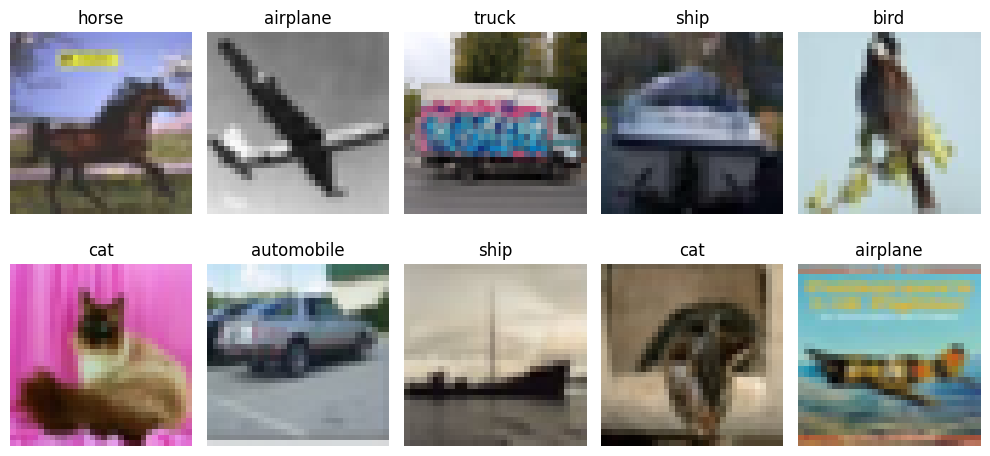

In [ ]:
(x_train_all,y_train_all),(x_test,y_test)=cifar10.load_data()
class_names=['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']
x_train_all=x_train_all.astype('float32')/255.0
x_test=x_test.astype('float32')/255.0
y_train_all=y_train_all.ravel(); y_test=y_test.ravel()
# Chia cố định: 45.000 train, 5.000 validation, 10.000 test
rng=np.random.default_rng(SEED)
indices=rng.permutation(len(x_train_all))
train_idx,val_idx=indices[5000:],indices[:5000]
x_train,y_train=x_train_all[train_idx],y_train_all[train_idx]
x_val,y_val=x_train_all[val_idx],y_train_all[val_idx]
print('Train:',x_train.shape,'Val:',x_val.shape,'Test:',x_test.shape)
fig,axs=plt.subplots(2,5,figsize=(10,5))
for i,ax in enumerate(axs.flat):
 ax.imshow(x_train[i]);ax.set_title(class_names[y_train[i]]);ax.axis('off')
plt.tight_layout();plt.savefig('outputs/cifar10_samples.png',dpi=150);plt.show()

In [ ]:
model=models.Sequential([
 layers.Input(shape=(32,32,3)),
 layers.Conv2D(32,3,padding='same',activation='relu'),layers.MaxPooling2D(),
 layers.Conv2D(64,3,padding='same',activation='relu'),layers.MaxPooling2D(),
 layers.Conv2D(128,3,padding='same',activation='relu'),layers.MaxPooling2D(),
 layers.Flatten(),layers.Dense(128,activation='relu'),layers.Dropout(0.3),
 layers.Dense(10,activation='softmax')
])
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),loss='sparse_categorical_crossentropy',metrics=['accuracy'])
model.summary()
callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=4,restore_best_weights=True),
           tf.keras.callbacks.ModelCheckpoint('outputs/best_cnn.keras',monitor='val_accuracy',save_best_only=True)]
history=model.fit(x_train,y_train,validation_data=(x_val,y_val),epochs=20,batch_size=128,callbacks=callbacks,verbose=1)
with open('outputs/history_cifar10.json','w') as f:json.dump({k:[float(v) for v in vals] for k,vals in history.history.items()},f,indent=2)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 356,810 (1.36 MB)

 Trainable params: 356,810 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 23s 41ms/step - accuracy: 0.3999 - loss: 1.6317 - val_accuracy: 0.4956 - val_loss: 1.3816
Epoch 2/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 22s 8ms/step - accuracy: 0.5558 - loss: 1.2523 - val_accuracy: 0.5860 - val_loss: 1.1335
Epoch 3/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.6183 - loss: 1.0836 - val_accuracy: 0.6512 - val_loss: 0.9657
Epoch 4/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.6620 - loss: 0.9711 - val_accuracy: 0.6758 - val_loss: 0.9088
Epoch 5/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.6886 - loss: 0.8935 - val_accuracy: 0.6960 - val_loss: 0.8617
Epoch 6/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.7154 - loss: 0.8247 - val_accuracy: 0.7216 - val_loss: 0.8103
Epoch 7/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.7276 - loss: 0.7796 - val_accuracy: 0.7210 - val_loss: 0.8009
Epoch 8/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.7485 - loss: 0.7207 - val_accuracy:

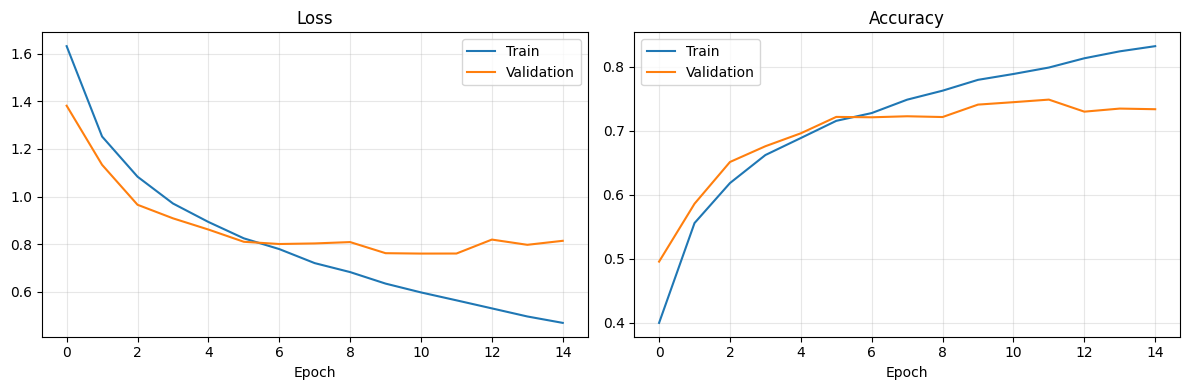

Test loss: 0.7788 | Test accuracy: 0.7436
              precision    recall  f1-score   support

    airplane       0.73      0.83      0.78      1000
  automobile       0.85      0.86      0.85      1000
        bird       0.68      0.64      0.66      1000
         cat       0.59      0.50      0.54      1000
        deer       0.71      0.65      0.68      1000
         dog       0.63      0.67      0.65      1000
        frog       0.82      0.79      0.80      1000
       horse       0.74      0.82      0.78      1000
        ship       0.82      0.87      0.85      1000
       truck       0.85      0.81      0.83      1000

    accuracy                           0.74     10000
   macro avg       0.74      0.74      0.74     10000
weighted avg       0.74      0.74      0.74     10000



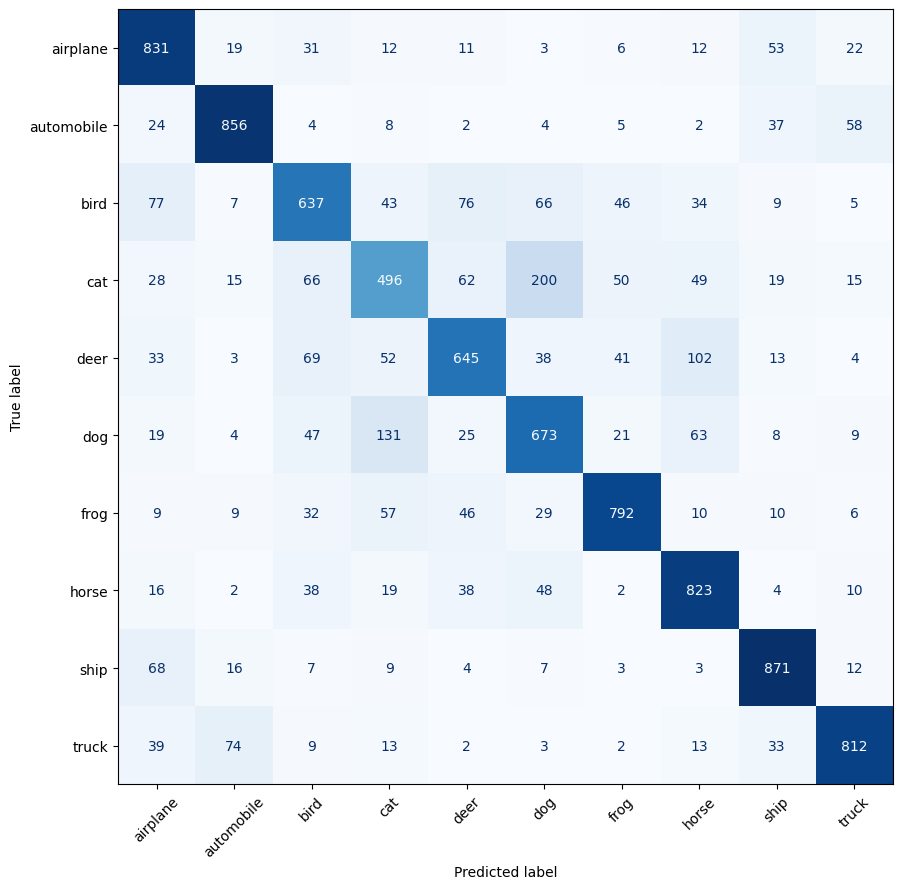

In [ ]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,metric in zip(axes,['loss','accuracy']):
 ax.plot(history.history[metric],label='Train');ax.plot(history.history['val_'+metric],label='Validation')
 ax.set_title(metric.capitalize());ax.set_xlabel('Epoch');ax.legend();ax.grid(alpha=.3)
plt.tight_layout();plt.savefig('outputs/cifar10_training.png',dpi=160);plt.show()
loss,accuracy=model.evaluate(x_test,y_test,verbose=0)
probs=model.predict(x_test,verbose=0);pred=probs.argmax(axis=1)
print(f'Test loss: {loss:.4f} | Test accuracy: {accuracy:.4f}')
print(classification_report(y_test,pred,target_names=class_names,zero_division=0))
fig,ax=plt.subplots(figsize=(10,9))
ConfusionMatrixDisplay.from_predictions(y_test,pred,display_labels=class_names,ax=ax,xticks_rotation=45,cmap='Blues',colorbar=False)
plt.tight_layout();plt.savefig('outputs/cifar10_confusion_matrix.png',dpi=160);plt.show()
with open('outputs/results_cifar10.json','w') as f:json.dump({'test_loss':float(loss),'test_accuracy':float(accuracy),'epochs_run':len(history.history['loss']),'seed':SEED},f,indent=2)

In [ ]:
import shutil
shutil.make_archive('cifar10_outputs','zip','outputs')
from google.colab import files
files.download('cifar10_outputs.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>